# Regression with tidymodels

This lesson is adapted from Chapter 10, "Regression", of:

> Downey, A. *Elements of Data Science.* <https://allendowney.github.io/ElementsOfDataScience/10_regression.html>

Licensed CC BY-NC-SA 4.0. The original uses Python and StatsModels. We do the same analysis in R with [tidymodels](https://www.tidymodels.org/).

## Setup

**tidymodels** is a set of R packages for fitting models the tidyverse way. You installed it with `pixi add r-tidymodels`. If the cell below fails, go back to the [guide](https://unc-bios-512.github.io/regression.html).

In [7]:
library('tidymodels')

── Attaching packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


## The data

We are using the [GSS](https://gss.norc.org/) data again. The General Social Survey has asked adults in the United States the same questions since 1972. Our subset has these columns:

| Column | Meaning |
| --- | --- |
| `year` | survey year |
| `age` | age in years |
| `educ` | years of school |
| `sex` | 1 = male, 2 = female |
| `realinc` | household income, in 1986 dollars |

In [8]:
gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse() 

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Models cannot use missing values. Drop rows with `NA` in the columns we need. Turn `sex` into a **factor** with labels, so R knows it is a category and not a number.

In [9]:
gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


In [10]:
gss <- gss |>
    drop_na(realinc, educ, age, sex) |>
    mutate(sex = factor(sex, levels = c(1, 2), labels = c('male', 'female')))

gss |> count(sex)

  sex    n    
1 male   30373
2 female 36908

  sex    n    
1 male   30373
2 female 36908

In [11]:
gss |> head()

  year id age educ sex    gunlaw grass realinc
1 1972 1  23  16   female 1      NA    18951  
2 1972 2  70  10   male   1      NA    24366  
3 1972 3  48  12   female 1      NA    24366  
4 1972 4  27  17   female 1      NA    30458  
5 1972 5  61  12   female 1      NA    50763  
6 1972 6  26  14   male   2      NA    43994  

## 10.1 Simple regression

How does income change with years of school? Look first. There are many people at each education level, so plot the mean income for each.

In [14]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

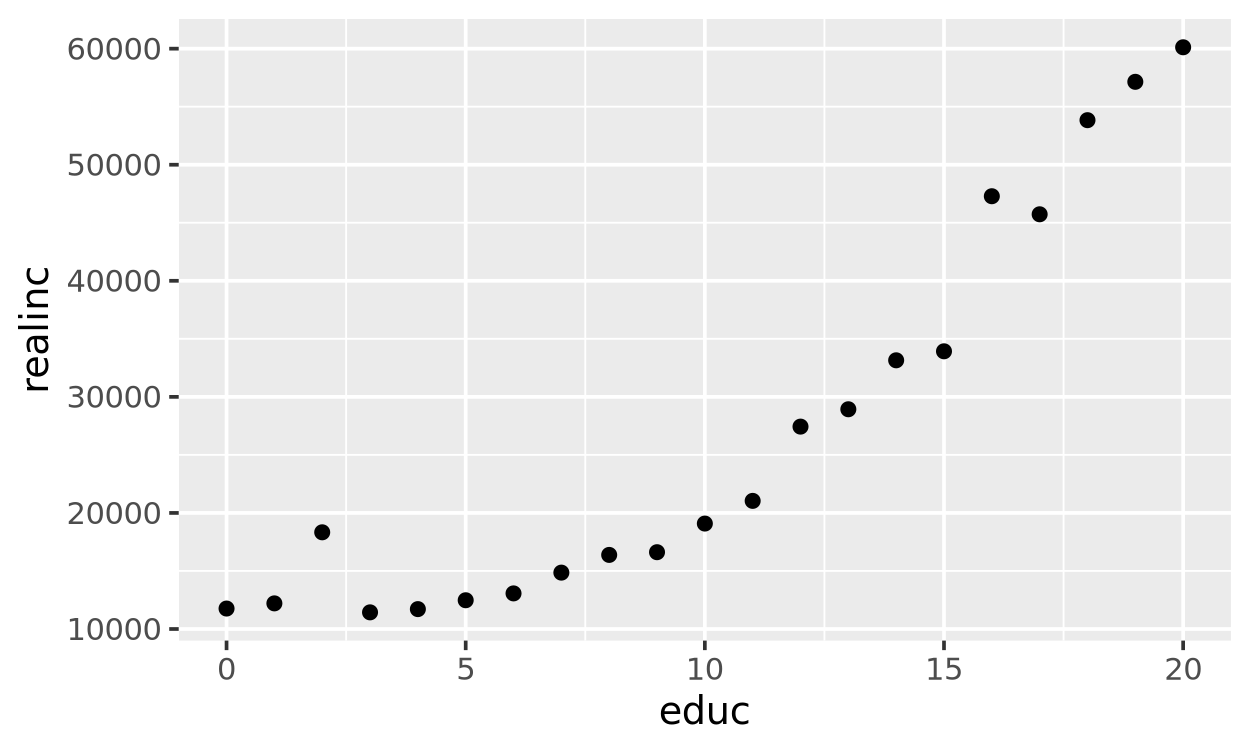

In [15]:
gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc)) |>
ggplot(aes(x = educ, y = realinc)) + geom_point()

A **linear regression** finds the straight line that fits best.

In tidymodels you say what kind of model you want, `linear_reg()`, then `fit()` it with a **formula**. The formula `realinc ~ educ` means: predict `realinc` from `educ`.

In [20]:
mod = linear_reg()
fit = mod |> fit(realinc ~ educ, data = gss)

fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14454         3575  


In [21]:
fit1 <- linear_reg() |> fit(realinc ~ educ, data = gss)

fit1

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14454         3575  


parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14454         3575  


In [22]:
fit1 |> tidy()

  term        estimate   std.error statistic p.value      
1 (Intercept) -14453.570 466.7002  -30.96971 4.104587e-209
2 educ          3575.344  34.5262  103.55451  0.000000e+00

  term        estimate   std.error statistic p.value      
1 (Intercept) -14453.570 466.7002  -30.96971 4.104587e-209
2 educ          3575.344  34.5262  103.55451  0.000000e+00

`tidy()` gives the coefficients as a table.

- The `educ` estimate is the **slope**. Each extra year of school goes with about $3,600 more income.
- The `(Intercept)` is the predicted income at 0 years of school. It is negative, which makes no sense. That is OK. Almost nobody in the data is near 0, so the line is not meant to be used there.

**You do:** fit the same kind of model with `age` instead of `educ`. What is the slope?

In [23]:
fit_age <- linear_reg() |> fit(realinc ~ age, data = gss)

fit_age |> tidy()

  term        estimate    std.error  statistic p.value     
1 (Intercept) 34373.10611 335.283705 102.51947 0.000000e+00
2 age           -39.67706   6.795122  -5.83905 5.273979e-09

  term        estimate    std.error  statistic p.value     
1 (Intercept) 34373.10611 335.283705 102.51947 0.000000e+00
2 age           -39.67706   6.795122  -5.83905 5.273979e-09

<details>
<summary>Answer</summary>

```r
fit_age <- linear_reg() |> fit(realinc ~ age, data = gss)

fit_age |> tidy()
```

</details>

## 10.2 Multiple regression

We can use more than one predictor. Add them with `+`.

In [24]:
fit2 <- linear_reg() |> fit(realinc ~ educ + age, data = gss)

fit2 |> tidy()

  term        estimate     std.error  statistic  p.value      
1 (Intercept) -16782.21042 583.711240 -28.750878 1.102648e-180
2 educ          3604.04344  34.784863 103.609533  0.000000e+00
3 age             42.21797   6.359664   6.638396  3.195143e-11

  term        estimate     std.error  statistic  p.value      
1 (Intercept) -16782.21042 583.711240 -28.750878 1.102648e-180
2 educ          3604.04344  34.784863 103.609533  0.000000e+00
3 age             42.21797   6.359664   6.638396  3.195143e-11

Now each slope means "holding the other one fixed".

- Holding age fixed, a year of school is worth about $3,700.
- Holding school fixed, a year of age is worth about $40.

## 10.3 Grouping by age

Is income really a straight line in age? Plot the mean income at each age.

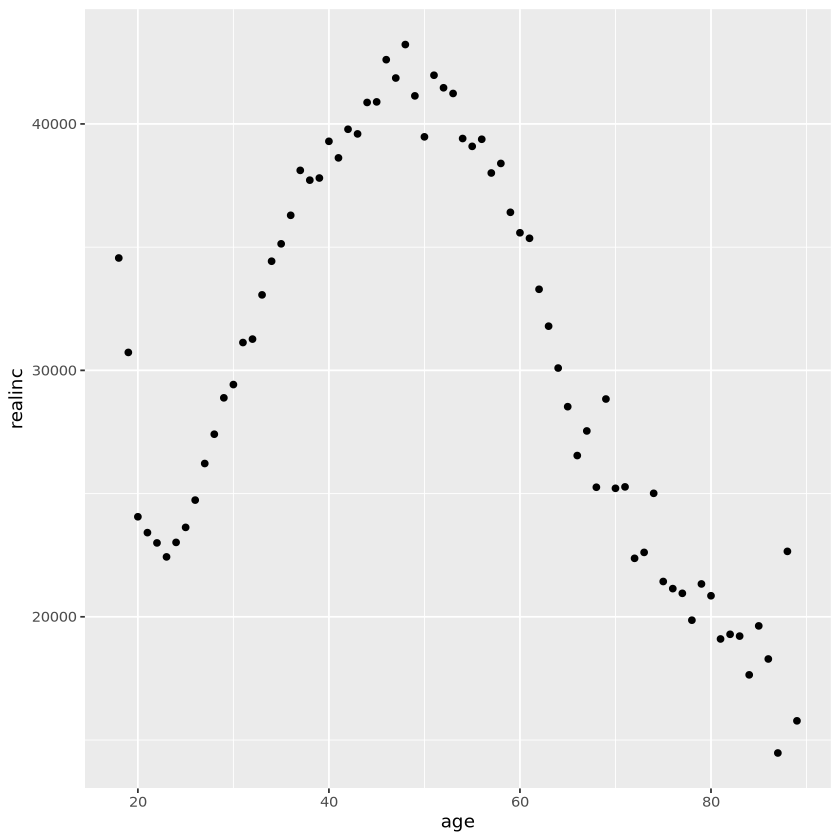

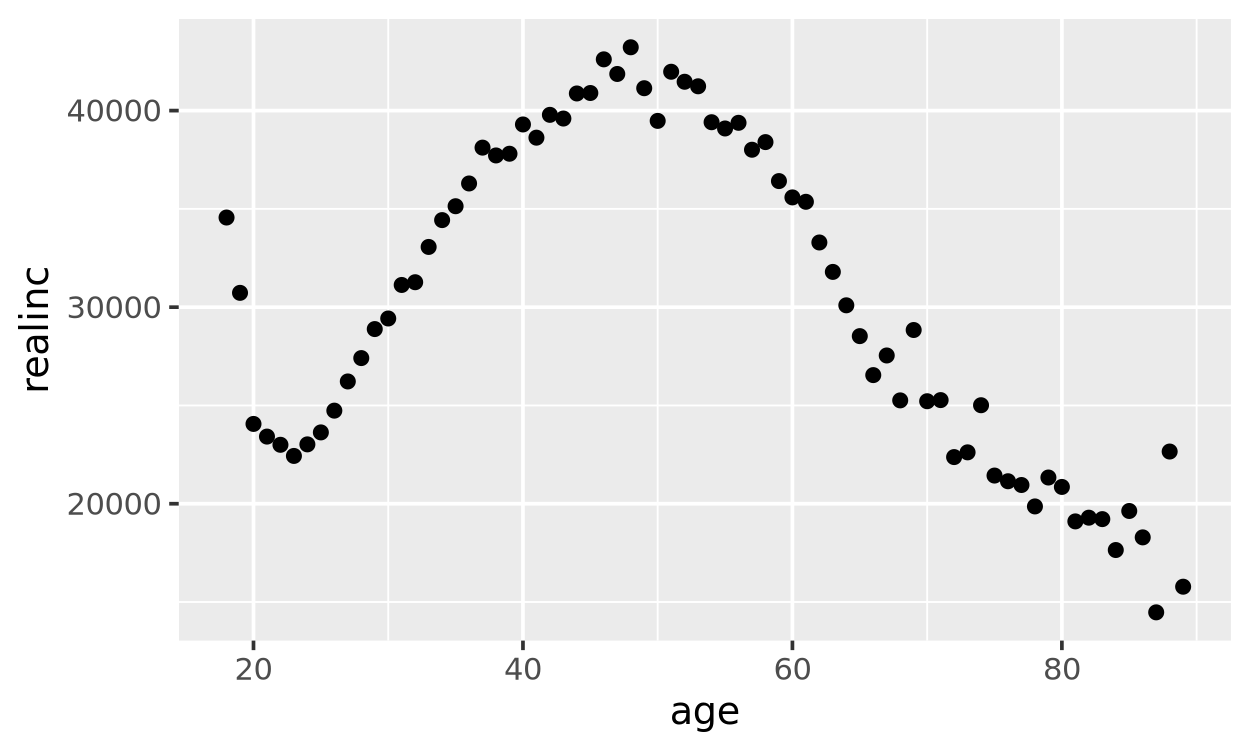

In [25]:
gss |>
    group_by(age) |>
    summarize(realinc = mean(realinc)) |>
ggplot(aes(x = age, y = realinc)) + geom_point()

Not a line. Income goes up until about 50, then down.

A straight line cannot bend. But a line plus a **squared** term can. Add a column `age2 = age^2` and put it in the model.

In [26]:
gss <- gss |> mutate(age2 = age^2)

fit3 <- linear_reg() |> fit(realinc ~ educ + age + age2, data = gss)

fit3 |> tidy()

  term        estimate     std.error   statistic p.value
1 (Intercept) -50853.29457 908.1857932 -55.99437 0      
2 educ          3412.21533  34.4238123  99.12369 0      
3 age           1734.09177  35.5107092  48.83292 0      
4 age2           -17.09117   0.3531232 -48.40003 0      

  term        estimate     std.error   statistic p.value
1 (Intercept) -50853.29457 908.1857932 -55.99437 0      
2 educ          3412.21533  34.4238123  99.12369 0      
3 age           1734.09177  35.5107092  48.83292 0      
4 age2           -17.09117   0.3531232 -48.40003 0      

The `age` slope is positive and the `age2` slope is negative. That makes a hill shape: up, then down.

**You do:** does the same trick help with education? Add `educ2 = educ^2` to `gss` and fit `realinc ~ educ + educ2 + age + age2`. Look back at the mean-income-by-education plot. Does a curve make sense there?

In [29]:
()gss <- gss |> mutate(educ2 = educ^2)

fit4 <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2, data = gss)

fit4 |> tidy()

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -25210.83874 1362.1520802 -18.508094  2.750820e-76
2 educ          -646.86871  164.9000260  -3.922793  8.761510e-05
3 educ2          161.03207    6.3991417  25.164636 4.317435e-139
4 age           1684.32532   35.4002974  47.579412  0.000000e+00
5 age2           -16.85073    0.3516053 -47.925122  0.000000e+00

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -25210.83874 1362.1520802 -18.508094  2.750820e-76
2 educ          -646.86871  164.9000260  -3.922793  8.761510e-05
3 educ2          161.03207    6.3991417  25.164636 4.317435e-139
4 age           1684.32532   35.4002974  47.579412  0.000000e+00
5 age2           -16.85073    0.3516053 -47.925122  0.000000e+00

<details>
<summary>Answer</summary>

```r
gss <- gss |> mutate(educ2 = educ^2)

fit4 <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2, data = gss)

fit4 |> tidy()
```

</details>

## 10.4 Visualizing predictions

Coefficients are hard to read. Pictures are easier.

First make sure we have the model with both squared terms.

In [30]:
gss <- gss |> mutate(educ2 = educ^2)

fit4 <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2, data = gss)

fit4 |> tidy()

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -25210.83874 1362.1520802 -18.508094  2.750820e-76
2 educ          -646.86871  164.9000260  -3.922793  8.761510e-05
3 educ2          161.03207    6.3991417  25.164636 4.317435e-139
4 age           1684.32532   35.4002974  47.579412  0.000000e+00
5 age2           -16.85073    0.3516053 -47.925122  0.000000e+00

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -25210.83874 1362.1520802 -18.508094  2.750820e-76
2 educ          -646.86871  164.9000260  -3.922793  8.761510e-05
3 educ2          161.03207    6.3991417  25.164636 4.317435e-139
4 age           1684.32532   35.4002974  47.579412  0.000000e+00
5 age2           -16.85073    0.3516053 -47.925122  0.000000e+00

Now ask the model to **predict** income for made-up people: every age from 18 to 89, with 12, 14, or 16 years of school. `expand_grid()` makes every combination.

In [38]:
grid <- expand_grid(age = 18:89, educ = c(12, 14, 16)) |>
    mutate(age2 = age^2, educ2 = educ^2)

grid |> head()

  age educ age2 educ2
1 18  12   324  144  
2 18  14   324  196  
3 18  16   324  256  
4 19  12   361  144  
5 19  14   361  196  
6 19  16   361  256  

  age educ age2 educ2
1 18  12   324  144  
2 18  14   324  196  
3 18  16   324  256  
4 19  12   361  144  
5 19  14   361  196  
6 19  16   361  256  

`predict()` takes the model and the new data. It returns one column, `.pred`. Glue it onto the grid with `bind_cols()`.

In [39]:
predict(fit4, grid) |> bind_cols(grid) |> head()

  .pred    age educ age2 educ2
1 15073.57 18  12   324  144  
2 22153.51 18  14   324  196  
3 30521.69 18  16   324  256  
4 16134.42 19  12   361  144  
5 23214.35 19  14   361  196  
6 31582.54 19  16   361  256  

In [40]:
preds <- fit4 |> predict(new_data = grid) |> bind_cols(grid)

preds |> head()

  .pred    age educ age2 educ2
1 15073.57 18  12   324  144  
2 22153.51 18  14   324  196  
3 30521.69 18  16   324  256  
4 16134.42 19  12   361  144  
5 23214.35 19  14   361  196  
6 31582.54 19  16   361  256  

  .pred    age educ age2 educ2
1 15073.57 18  12   324  144  
2 22153.51 18  14   324  196  
3 30521.69 18  16   324  256  
4 16134.42 19  12   361  144  
5 23214.35 19  14   361  196  
6 31582.54 19  16   361  256  

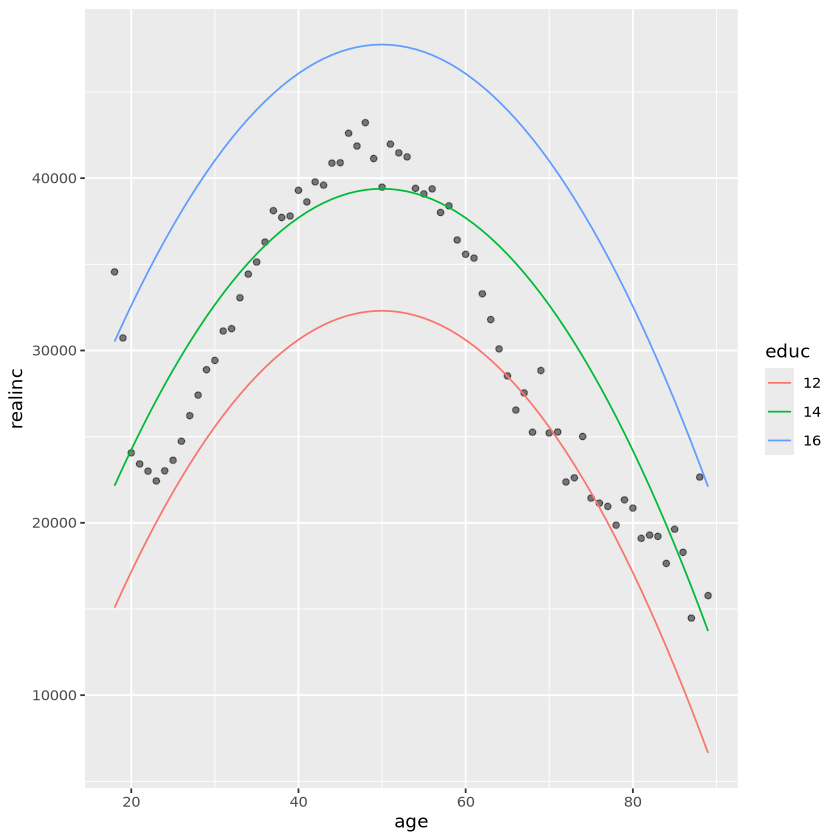

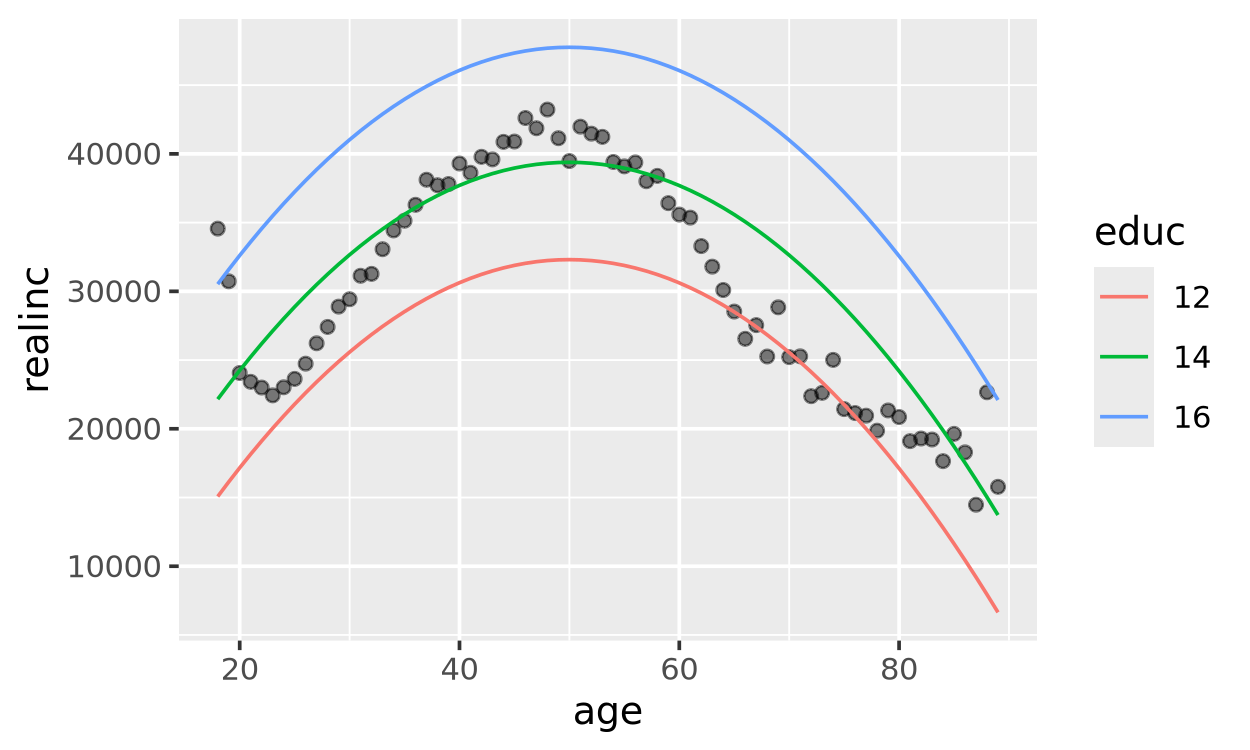

In [42]:
income_by_age <- gss |>
    group_by(age) |>
    summarize(realinc = mean(realinc))

ggplot() +
    geom_point(data = income_by_age, aes(x = age, y = realinc), alpha = 0.5) +
    geom_line(data = preds, aes(x = age, y = .pred, color = factor(educ))) +
    labs(color = 'educ')

**You do:** make a grid with `educ = 0:20` and `age = 30`. Do not forget `age2` and `educ2`. Predict with `fit4`. Then draw the line over the mean-income-by-education points.

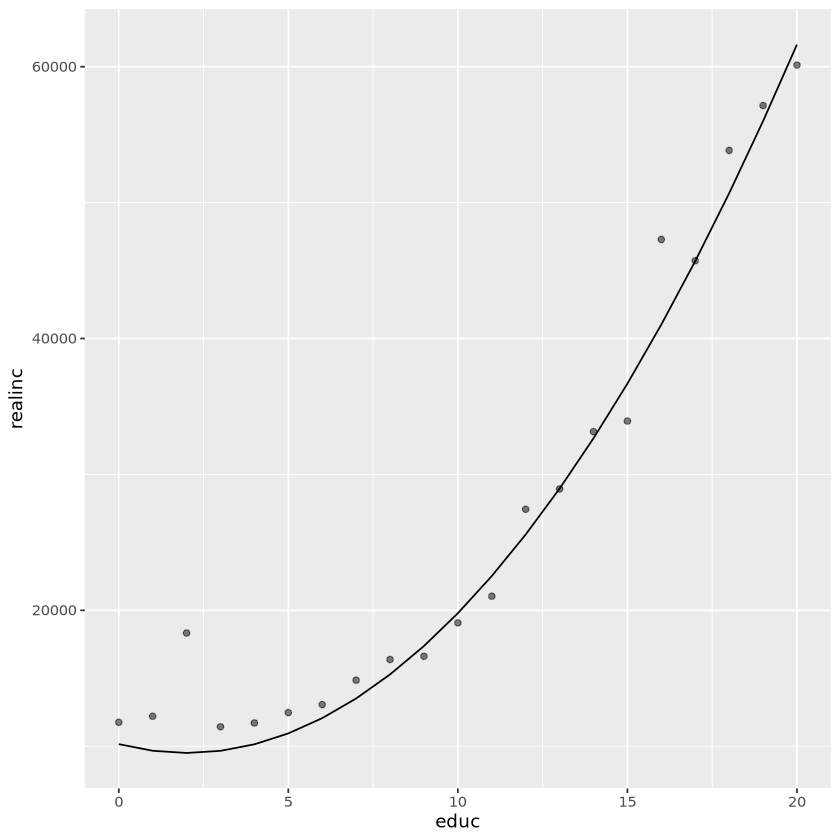

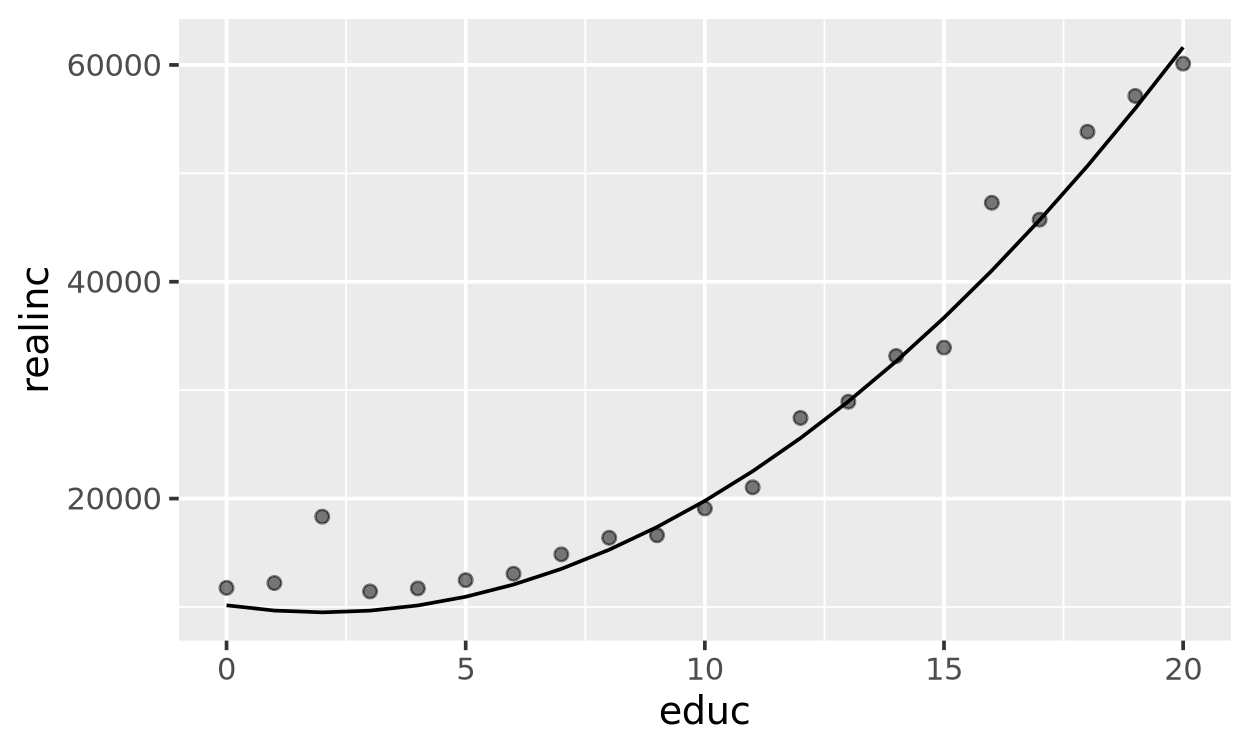

In [43]:
grid_educ <- expand_grid(educ = 0:20, age = 30) |>
    mutate(age2 = age^2, educ2 = educ^2)

preds_educ <- fit4 |> predict(new_data = grid_educ) |> bind_cols(grid_educ)

income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

ggplot() +
    geom_point(data = income_by_educ, aes(x = educ, y = realinc), alpha = 0.5) +
    geom_line(data = preds_educ, aes(x = educ, y = .pred))

<details>
<summary>Answer</summary>

```r
grid_educ <- expand_grid(educ = 0:20, age = 30) |>
    mutate(age2 = age^2, educ2 = educ^2)

preds_educ <- fit4 |> predict(new_data = grid_educ) |> bind_cols(grid_educ)

income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

ggplot() +
    geom_point(data = income_by_educ, aes(x = educ, y = realinc), alpha = 0.5) +
    geom_line(data = preds_educ, aes(x = educ, y = .pred))
```

</details>

## 10.5 Categorical variables

`sex` is not a number. It is a **category**. R can still use it in a formula.

In [19]:
fit5 <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2 + sex, data = gss)

fit5 |> tidy()

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -23492.32854 1358.9295903 -17.287377  8.170559e-67
2 educ          -445.29142  164.4946313  -2.707027  6.790585e-03
3 educ2          152.28913    6.3856783  23.848544 3.479570e-125
4 age           1677.72078   35.2640394  47.575967  0.000000e+00
5 age2           -16.75765    0.3502638 -47.842932  0.000000e+00
6 sexfemale    -4906.99476  213.8692633 -22.943899 4.740990e-116

The row is called `sexfemale`, not `sex`. Its estimate is about −$4,900. That means: holding age and school fixed, women report about $4,900 less income than men.

Careful: `realinc` is **household** income, not personal income. So this is not a direct measure of the gender pay gap.

### How R encodes a factor

A model can only multiply numbers. So R turns `sex` into a 0/1 column behind the scenes. This is called a **dummy variable**.

The first level, `male`, is the **baseline**. It gets no column. The column `sexfemale` is 1 for women and 0 for men. Let's look.

In [20]:
contrasts(gss$sex)

       female
male   0     
female 1     

That is the lookup table. Now see the columns R builds for the first few rows. Compare them with the `sex` column.

In [21]:
head(gss) |> select(sex)

  sex   
1 female
2 male  
3 female
4 female
5 female
6 male  

In [22]:
model.matrix(~ sex, data = head(gss))

  (Intercept) sexfemale
1 1           1        
2 1           0        
3 1           1        
4 1           1        
5 1           1        
6 1           0        

And here is the full table the model actually used. tidymodels wraps a plain `lm` object. `extract_fit_engine()` pulls it out.

In [23]:
fit5 |> extract_fit_engine() |> model.matrix() |> head()

  (Intercept) educ educ2 age age2 sexfemale
1 1           16   256   23   529 1        
2 1           10   100   70  4900 0        
3 1           12   144   48  2304 1        
4 1           17   289   27   729 1        
5 1           12   144   61  3721 1        
6 1           14   196   26   676 0        

Each coefficient in `tidy(fit5)` multiplies one of these columns. The `sexfemale` coefficient is just "how much to add when that column is 1".

tidymodels can also make dummy columns by hand with `recipe() |> step_dummy()`. Here the formula does it for us.

**You do:** what if `sex` were a plain number (1 and 2) instead of a factor? Refit with `as.numeric(sex)` and compare the `tidy()` tables.

In [24]:
fit5b <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2 + as.numeric(sex), data = gss)

fit5b |> tidy()

  term            estimate     std.error    statistic  p.value      
1 (Intercept)     -18585.33378 1387.2517925 -13.397232  7.082129e-41
2 educ              -445.29142  164.4946313  -2.707027  6.790585e-03
3 educ2              152.28913    6.3856783  23.848544 3.479570e-125
4 age               1677.72078   35.2640394  47.575967  0.000000e+00
5 age2               -16.75765    0.3502638 -47.842932  0.000000e+00
6 as.numeric(sex)  -4906.99476  213.8692633 -22.943899 4.740990e-116

<details>
<summary>Answer</summary>

```r
fit5b <- linear_reg() |> fit(realinc ~ educ + educ2 + age + age2 + as.numeric(sex), data = gss)

fit5b |> tidy()

# The slope is the same size. Only the intercept moves, because the
# baseline is now 0 instead of 1. With two levels that works. With three
# or more levels a plain number would force them onto a line in a made-up
# order. A factor avoids that.
```

</details>

## Turn in

You turn in this notebook, with the outputs from live coding in class.

1. Save the notebook with **Ctrl+S**. Every cell should show its output.
2. Commit and push to your fork. See steps 6 and 7 of the [guide](https://unc-bios-512.github.io/regression.html).
3. Open the notebook on GitHub and paste its link into the Canvas assignment.